# 1. Tratamento e análise exploratória da pobreza em Oaxaca

**570 municípios | 2010–2020 | Econometria Espacial**

O roteiro prepara a base, descreve a mudança da pobreza e examina a associação espacial. Cada análise aparece em um bloco explícito, com resultados impressos no console e interpretação logo abaixo. As figuras são seguidas de sua leitura substantiva. Os CSVs guardam os resultados detalhados para conferência.

Execute todas as células em um kernel limpo. O segundo notebook lerá a camada exportada ao final. Os laços técnicos deste notebook conferem a integridade dos dados e localizam os arquivos. Se os dados ou parâmetros mudarem, execute novamente e revise as interpretações.

Referências do projeto e da disciplina estão na [proposta](../docs/Proposta_Projeto_Pobreza_Oaxaca.pdf), na [SPEC](../docs/SPEC.md) e nas [aulas](../docs/aulas_scripts/).

## 1. Preparação

Importamos os pacotes das aulas. NumPy e pandas tratam os valores; GeoPandas e Shapely tratam a geografia; libpysal constrói a vizinhança; ESDA calcula Moran. As figuras usam Matplotlib/Seaborn. Nenhum pacote é instalado pelo notebook.

Os parâmetros são únicos: significância de 5%, 999 permutações e semente 42. A projeção EPSG:6372 cobre Oaxaca e usa metros; ela será necessária para centroides e distâncias.

A saída registra as versões das bibliotecas para localizar diferenças de API em uma eventual reprodução. Os 999 embaralhamentos dão ao p-valor de permutação resolução de 0,001. A semente fixa permite repetir a análise com a mesma versão e configuração.

In [1]:
# Importando as bibliotecas de tratamento e análise espacial
from pathlib import Path
import sys
import hashlib
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import libpysal
import esda
from shapely import make_valid, hausdorff_distance
from shapely.validation import explain_validity

# Fixando o nível dos testes, a semente e a projeção métrica
ALFA, PERMUTACOES, SEMENTE = .05, 999, 42
CRS_METRICO = 'EPSG:6372'
sns.set_theme(style='whitegrid')
print('Python:', sys.version.split()[0])
print('NumPy:', metadata.version('numpy'), '| pandas:', metadata.version('pandas'))
print('GeoPandas:', metadata.version('geopandas'), '| Shapely:', metadata.version('shapely'))
print('libpysal:', metadata.version('libpysal'), '| ESDA:', metadata.version('esda'))

Python: 3.14.3
NumPy: 2.4.3 | pandas: 3.0.1
GeoPandas: 1.2.0 | Shapely: 2.2.0
libpysal: 4.15.1 | ESDA: 2.10.0


### 1.1 Caminhos e preservação dos inputs

Procuramos a raiz pelo README e pela pasta data, permitindo começar tanto na raiz como em src. Os dados brutos e os materiais de referência são somente lidos. O SHA-256 identifica a versão local de cada um dos 21 inputs; datas de aquisição desconhecidas não são deduzidas das datas do Windows.

O GeoPackage e o dicionário vão para `data/processed/`. As tabelas e figuras vão para diretórios distintos em `outputs/`. A tabela de procedência vincula cada caminho relativo ao hash correspondente, que será recalculado ao final.

In [2]:
# Localizando a raiz do projeto pelos marcadores de diretório
for pasta in [Path.cwd(), *Path.cwd().parents]:
    if (pasta / 'README.md').is_file() and (pasta / 'data').is_dir():
        raiz = pasta
        break
assert (raiz / 'docs' / 'SPEC.md').is_file()
brutos, tratados = raiz / 'data/raw', raiz / 'data/processed'
tabelas, figuras = raiz / 'outputs/tables', raiz / 'outputs/figures'
for pasta in [tratados, tabelas, figuras]:
    pasta.mkdir(parents=True, exist_ok=True)

# Registrando os hashes para conferir a preservação dos arquivos de origem
arquivos = [*brutos.glob('*'), raiz / 'docs/Proposta_Projeto_Pobreza_Oaxaca.pdf',
    *(raiz / 'docs/aulas_slides').glob('*'), *(raiz / 'docs/aulas_scripts').glob('*')]
hashes_iniciais = {p.relative_to(raiz).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in sorted(arquivos) if p.is_file()}
procedencia = pd.DataFrame(hashes_iniciais.items(), columns=['arquivo', 'sha256'])
procedencia['data_aquisicao'] = 'desconhecida'
procedencia.to_csv(tabelas / 'procedencia_inputs.csv', index=False, encoding='utf-8-sig')
print(len(procedencia), 'inputs registrados.')

21 inputs registrados.


## 2. Leitura e conferência dos atributos

O GeoJSON é a entrada principal; o Shapefile é uma representação alternativa para comparação, sem duplicar municípios. O DBF é lido explicitamente como UTF-8, pois falta o arquivo .cpg e a leitura padrão pode distorcer acentos.

mun é o código dentro de Oaxaca, de 1 a 570. Ele será textual, com três posições, e determinará a ordem dos dados e dos pesos. ID contém o código estadual/municipal. Os dicionários originais em data/raw e o dicionário analítico da seção final documentam conceitos e denominadores.

Depois de ordenar o GeoJSON por `mun`, usamos essa lista para reordenar o Shapefile. A comparação numérica tolera diferenças de arredondamento entre formatos. A correspondência de códigos e nomes é exata, o que evita comparar atributos de municípios diferentes.

In [3]:
# Lendo os formatos de origem e conferindo os 570 códigos municipais
dados = gpd.read_file(brutos / 'oaxaca.geojson')
shapefile = gpd.read_file(brutos / 'oaxaca.shp', encoding='utf-8')
assert len(dados) == len(shapefile) == 570
assert dados['mun'].is_unique and dados['mun_name'].notna().all()
assert set(dados['mun'].astype(int)) == set(range(1, 571))
# Padronizando a chave e alinhando o Shapefile à ordem do GeoJSON
for base in [dados, shapefile]:
    base['mun'] = base['mun'].astype(int).astype(str).str.zfill(3)
dados = dados.sort_values('mun').reset_index(drop=True)
shapefile = shapefile.set_index('mun').loc[dados['mun']].reset_index()
assert (dados['ID'] == 20000 + dados['mun'].astype(int)).all()
assert dados['mun_name'].equals(shapefile['mun_name'])

# Comparando os atributos usados na análise com tolerância numérica
campos_numericos = ['ID', 'pepov_10', 'pepov_20', 'ppov_10', 'ppov_20',
    'GRAD10', 'p_PIND10', 'p_PHA10', 'PTOT10', 'ALTID', 'PIND10', 'P5U10', 'PHA10',
    'p_P15AN00', 'p_ELEC00', 'p_NODIR00', 'P15AN00', 'P15U00', 'ELEC00', 'NODIR00', 'HOMS00']
for campo in campos_numericos:
    dados[campo] = pd.to_numeric(dados[campo], errors='raise')
    assert np.allclose(dados[campo], shapefile[campo], atol=1e-8, rtol=1e-10, equal_nan=True)
print('570 códigos e nomes conferidos; atributos necessários equivalentes entre formatos.')

570 códigos e nomes conferidos; atributos necessários equivalentes entre formatos.


### 2.1 Ausências, limites e denominadores

Percentuais devem estar entre 0 e 100; os denominadores e a população usada no logaritmo devem ser positivos. Ausências serão tratadas por casos completos, sem imputação; valores inválidos interrompem a execução. Não há winsorização ou truncamento.

Conferimos os campos p_ contra 100 vezes o numerador dividido pelo denominador. Essa verificação evita multiplicar novamente percentuais já expressos em 0–100. p_PHA10 mede acesso à saúde, e não a carência de acesso medida por pheal_10.

Na saída, `n_ausentes` conta valores faltantes e `n_invalidos` conta registros fora das regras. Mínimo e máximo permitem conferir a escala de cada indicador. As verificações dos denominadores incluem a população censitária e as populações de referência por idade e domicílio.

In [4]:
# Auditando a faixa dos percentuais e a positividade dos denominadores
percentuais = ['pepov_10', 'pepov_20', 'ppov_10', 'ppov_20', 'p_PIND10', 'p_PHA10',
    'p_P15AN00', 'p_ELEC00', 'p_NODIR00']
positivos = ['PTOT10', 'P5U10', 'P15U00', 'HOMS00']
auditoria = []
for campo in campos_numericos:
    valores = dados[campo]
    invalidos = valores.notna() & ~np.isfinite(valores)
    if campo in percentuais:
        invalidos |= valores.notna() & ~valores.between(0, 100)
    else:
        invalidos |= valores.notna() & (valores < 0)
    if campo in positivos:
        invalidos |= valores.notna() & (valores <= 0)
    auditoria.append({'verificacao': campo, 'n_ausentes': valores.isna().sum(),
        'n_invalidos': invalidos.sum(), 'minimo': valores.min(), 'maximo': valores.max()})
    assert not invalidos.any(), f'Valores inválidos em {campo}.'

# Recalculando os percentuais a partir dos totais censitários
formulas = [('p_PIND10', 'PIND10', 'P5U10'), ('p_PHA10', 'PHA10', 'PTOT10'),
    ('p_P15AN00', 'P15AN00', 'P15U00'), ('p_ELEC00', 'ELEC00', 'HOMS00'),
    ('p_NODIR00', 'NODIR00', 'HOMS00')]
for percentual, numerador, denominador in formulas:
    erro = (dados[percentual] - 100 * dados[numerador] / dados[denominador]).abs()
    assert erro.dropna().max() < 1e-6, percentual
print('Campos auditados:', len(campos_numericos))
print('Valores ausentes:', sum(item['n_ausentes'] for item in auditoria))
print('Valores fora das regras:', sum(item['n_invalidos'] for item in auditoria))
print('Diferença entre percentuais e fórmulas censitárias abaixo de 0,000001')

Campos auditados: 21
Valores ausentes: 0
Valores fora das regras: 0
Diferença entre percentuais e fórmulas censitárias abaixo de 0,000001


**Leitura da auditoria.** Os 21 campos numéricos conferidos estão completos e respeitam as regras de validade. Os percentuais já se encontram na escala de 0 a 100. As fórmulas censitárias confirmam a população de referência de cada proporção, condição necessária para comparar os municípios.

## 3. Geometria e projeção

As sete geometrias identificadas anteriormente têm anéis externos aninhados. Aplicamos o reparo autorizado apenas à cópia tratada e exigimos que todas se tornem válidas. A Queen antes/depois deve preservar exatamente os mesmos vizinhos: não acrescentamos ligações artificiais nem excluímos municípios.

EPSG:6372 é uma projeção métrica para o México. A reprojeção ocorre antes de áreas, centroides e distâncias. Os arquivos originais continuam intactos.

A célula registra a lista de vizinhos antes de modificar a geometria e a compara com a lista posterior ao reparo. As versões projetadas da malha tratada, do Shapefile e das geometrias anteriores servirão à auditoria em metros e metros quadrados.

In [5]:
# Registrando a vizinhança Queen antes do reparo
ids = dados['mun'].tolist()
queen_antes = libpysal.weights.Queen.from_dataframe(dados, ids=ids)
invalida = ~dados.geometry.is_valid
assert set(dados.loc[invalida, 'mun']) == {'042', '057', '183', '205', '211', '327', '470'}
assert shapefile.geometry.is_valid.all()
# Reparando apenas as sete geometrias autorizadas
geometria_antes = dados.geometry.copy()
dados.loc[invalida, 'geometry'] = dados.loc[invalida, 'geometry'].map(make_valid)
assert dados.geometry.is_valid.all() and not dados.geometry.is_empty.any()
queen_depois = libpysal.weights.Queen.from_dataframe(dados, ids=ids)
# Comparando os conjuntos de vizinhos sem depender da ordem interna das listas
assert all(set(queen_antes.neighbors[i]) == set(queen_depois.neighbors[i]) for i in ids)

# Projetando as malhas em metros antes de medir distâncias e áreas
mapa = dados.to_crs(CRS_METRICO)
shp_metrico = shapefile.to_crs(CRS_METRICO)
antes_metrico = gpd.GeoSeries(geometria_antes, crs=dados.crs).to_crs(CRS_METRICO)
assert mapa.crs.is_projected and all(a.unit_name == 'metre' for a in mapa.crs.axis_info)
print('CRS:', mapa.crs.name, '| área de uso:', mapa.crs.area_of_use)

CRS: Mexico ITRF2008 / LCC | área de uso: - name: Mexico - onshore and offshore.
- bounds: (-122.19, 12.1, -84.64, 32.72)


### 3.1 Registro das alterações geométricas

O console informa os sete códigos reparados, o maior deslocamento de centroide e o número de geometrias válidas. O CSV de reparos registra motivo, tipo, área e deslocamento por município. A área anterior provém de geometria inválida e exige essa ressalva na comparação.

Conferimos as 570 geometrias tratadas com o Shapefile válido por distância Hausdorff inferior a 1 cm e diferença simétrica relativa inferior a 1e-8. A distância entre centroides está em metros. Essas verificações complementam a preservação das ligações Queen.

In [6]:
# Medindo a mudança de área e de centroide em cada reparo
reparos = []
for i in dados.index[invalida]:
    antes, depois = antes_metrico.iloc[i], mapa.geometry.iloc[i]
    reparos.append({'mun': dados.loc[i, 'mun'], 'municipio': dados.loc[i, 'mun_name'],
        'motivo': explain_validity(geometria_antes.iloc[i]),
        'tipo_antes': geometria_antes.iloc[i].geom_type, 'tipo_depois': depois.geom_type,
        'area_antes_m2_invalida': antes.area, 'area_depois_m2': depois.area,
        'variacao_area_relativa': depois.area / antes.area - 1,
        'deslocamento_centroide_m': antes.centroid.distance(depois.centroid)})
reparos = pd.DataFrame(reparos)
reparos.to_csv(tabelas / 'reparos_geometrias.csv', index=False, encoding='utf-8-sig')
# Conferindo o contorno e a sobreposição em relação ao Shapefile válido
for a, b in zip(mapa.geometry, shp_metrico.geometry):
    assert hausdorff_distance(a, b) < .01
    assert a.symmetric_difference(b).area / max(a.area, b.area) < 1e-8
auditoria.append({'verificacao': 'geometrias reparadas', 'n_invalidos': int(invalida.sum()),
    'acao': 'sete make_valid; 570 válidas; Queen preservada; equivalência métrica com Shapefile'})
print('Municípios reparados:', reparos.mun.tolist())
print('Maior deslocamento do centroide em metros:', reparos.deslocamento_centroide_m.max())
print('Geometrias válidas após o tratamento:', dados.geometry.is_valid.sum())
print('Vizinhança Queen preservada e correspondência com o Shapefile conferida')

Municípios reparados: ['042', '057', '183', '205', '211', '327', '470']
Maior deslocamento do centroide em metros: 822.6008731480978
Geometrias válidas após o tratamento: 570
Vizinhança Queen preservada e correspondência com o Shapefile conferida


**Leitura dos reparos.** Os sete municípios autorizados foram reparados e os 570 polígonos finais são válidos. As diferenças de área anteriores ao tratamento precisam ser lidas considerando a invalidade das geometrias de origem. A conferência das ligações garante que o reparo conserva a estrutura Queen. O CSV registra as alterações individualmente.

## 4. Variáveis derivadas e amostras

delta_pepov e delta_ppov são diferenças 2020 menos 2010, em pontos percentuais: negativo significa redução. ln_ptot10 é o logaritmo natural da população positiva. Os controles socioeconômicos são de 2010.

O regime vale 1 quando pelo menos 50% da população de 5 anos ou mais fala língua indígena. Não é uma classificação étnica individual. ALTID é a exceção temporal: média da altitude das localidades de 2020, usada como aproximação geográfica fixa. A unidade em metros é inferida da convenção INEGI; o dicionário GeoDa não informa unidade ou agregação.

Para cada desfecho, consideramos a mudança, seu nível inicial e os cinco controles. O indicador vale 1 quando todos esses campos são finitos. O CSV de amostras registra o motivo por município e desfecho. A interseção identifica quais municípios podem ser comparados nas duas especificações.

In [7]:
# Calculando as mudanças em pontos percentuais e o tamanho populacional em logaritmo
dados['delta_pepov'] = dados['pepov_20'] - dados['pepov_10']
dados['delta_ppov'] = dados['ppov_20'] - dados['ppov_10']
dados['ln_ptot10'] = np.log(dados['PTOT10'])
dados['regime_indigena'] = (dados['p_PIND10'] >= 50).astype('int64')
controles = ['GRAD10', 'p_PIND10', 'p_PHA10', 'ln_ptot10', 'ALTID']

# Identificando os casos completos de cada desfecho
campos_extrema = ['delta_pepov', 'pepov_10', *controles]
campos_total = ['delta_ppov', 'ppov_10', *controles]
dados['amostra_extrema'] = np.isfinite(dados[campos_extrema]).all(axis=1).astype('int64')
dados['amostra_total'] = np.isfinite(dados[campos_total]).all(axis=1).astype('int64')
dados['amostra_comum'] = (dados.amostra_extrema.eq(1) & dados.amostra_total.eq(1)).astype('int64')

# Conferindo a cobertura antes de preparar as análises explícitas desta base
assert dados[['amostra_extrema', 'amostra_total']].eq(1).all().all(), 'Cobertura mudou: revisar amostras e registrar perdas antes de prosseguir'
amostra_extrema = pd.DataFrame({'mun': dados.mun, 'desfecho': 'extrema',
    'incluido': dados.amostra_extrema, 'motivo': 'caso completo'})
amostra_total = pd.DataFrame({'mun': dados.mun, 'desfecho': 'total',
    'incluido': dados.amostra_total, 'motivo': 'caso completo'})
pd.concat([amostra_extrema, amostra_total]).to_csv(tabelas / 'amostras_municipais.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(auditoria).to_csv(tabelas / 'auditoria_dados.csv', index=False, encoding='utf-8-sig')
print('Amostra de pobreza extrema:', dados.amostra_extrema.sum())
print('Amostra de pobreza total:', dados.amostra_total.sum())
print('Amostra comum:', dados.amostra_comum.sum())
print('Municípios por regime:', dados.regime_indigena.value_counts().sort_index().to_dict())

Amostra de pobreza extrema: 570
Amostra de pobreza total: 570
Amostra comum: 570
Municípios por regime: {0: 348, 1: 222}


**Leitura das amostras.** Os dois desfechos têm os mesmos 570 municípios. As comparações usam cobertura idêntica, e as diferenças de resultados podem ser examinadas em relação ao desfecho e à vizinhança. O grupo abaixo de 50% de falantes de língua indígena tem 348 municípios, enquanto o grupo com pelo menos 50% tem 222. Essa divisão será usada nos regimes do segundo notebook.

## 5. Estatísticas e distribuição geográfica

Cada município recebe o mesmo peso. Imprimimos os resumos nativos das séries de pobreza extrema em 2010, em 2020 e da mudança em pontos percentuais. Em cada resumo, count é o número de casos, mean é a média, std é o desvio-padrão e os percentis mostram a distribuição.

O CSV de descritivas preserva os dois desfechos e controles com suas unidades. O bloco seguinte imprime a pobreza total e os controles separadamente. Os mapas posteriores compartilham classes entre anos e usam uma escala divergente centrada em zero para as mudanças.

In [8]:
# Resumindo os níveis, as mudanças e os controles em suas unidades originais
variaveis = ['pepov_10', 'pepov_20', 'delta_pepov', 'ppov_10', 'ppov_20', 'delta_ppov', *controles]
unidades = dict.fromkeys(['pepov_10', 'pepov_20', 'ppov_10', 'ppov_20', 'p_PIND10', 'p_PHA10'], '%')
unidades.update({'delta_pepov': 'p.p.', 'delta_ppov': 'p.p.', 'GRAD10': 'anos de estudo',
    'ln_ptot10': 'ln(pessoas)', 'ALTID': 'metros; unidade inferida'})
descritivas = dados[variaveis].describe().T.rename_axis('variavel').reset_index()
descritivas['unidade'] = descritivas['variavel'].map(unidades)
descritivas.to_csv(tabelas / 'estatisticas_descritivas.csv', index=False, encoding='utf-8-sig')

print("Resumo dos níveis e mudanças de pobreza extrema")
print(dados.pepov_10.describe())
print(dados.pepov_20.describe())
print(dados.delta_pepov.describe())

Resumo dos níveis e mudanças de pobreza extrema
count    570.000000
mean      43.492632
std       21.287397
min        1.100000
25%       26.500000
50%       43.400000
75%       61.125000
max       90.100000
Name: pepov_10, dtype: float64
count    570.000000
mean      28.709825
std       16.888957
min        1.000000
25%       15.400000
50%       25.500000
75%       40.775000
max       84.400000
Name: pepov_20, dtype: float64
count    570.000000
mean     -14.782807
std       14.058446
min      -58.800000
25%      -24.300000
50%      -12.800000
75%       -4.600000
max       37.300000
Name: delta_pepov, dtype: float64


**Leitura das descritivas da pobreza extrema.** As médias municipais são 43,49% em 2010 e 28,71% em 2020. A mudança média de −14,78 p.p. convive com variações de −58,8 a +37,3 p.p. O desvio-padrão das mudanças é 14,06 p.p., mostrando heterogeneidade das trajetórias. Os resumos atribuem o mesmo peso a municípios de tamanhos populacionais diferentes.

### 5.1 Descritivas da pobreza total e dos controles

Imprimimos os resumos nativos das séries para distinguir as unidades e escalas. A média, o desvio-padrão e os quartis da pobreza total usam os mesmos municípios do desfecho principal. Os controles serão interpretados em suas unidades originais na regressão.

In [9]:
# Resumindo a pobreza total e os controles nas suas escalas originais
print('Pobreza total em 2010')
print(dados.ppov_10.describe())
print('Pobreza total em 2020')
print(dados.ppov_20.describe())
print('Mudança da pobreza total em p.p.')
print(dados.delta_ppov.describe())
print('Escolaridade em anos')
print(dados.GRAD10.describe())
print('Falantes de língua indígena em %')
print(dados.p_PIND10.describe())
print('Acesso à saúde em %')
print(dados.p_PHA10.describe())
print('Logaritmo da população')
print(dados.ln_ptot10.describe())
print('Altitude das localidades de 2020')
print(dados.ALTID.describe())

Pobreza total em 2010
count    570.000000
mean      82.077193
std       15.270909
min       20.200000
25%       75.800000
50%       87.000000
75%       93.500000
max       99.000000
Name: ppov_10, dtype: float64
Pobreza total em 2020
count    570.000000
mean      77.324912
std       18.152290
min       16.900000
25%       67.925000
50%       82.200000
75%       91.875000
max       99.600000
Name: ppov_20, dtype: float64
Mudança da pobreza total em p.p.
count    570.000000
mean      -4.752281
std        8.153046
min      -36.700000
25%       -9.600000
50%       -3.650000
75%        0.300000
max       52.900000
Name: delta_ppov, dtype: float64
Escolaridade em anos
count    570.000000
mean       5.776947
std        1.428784
min        2.320000
25%        4.900000
50%        5.530000
75%        6.407500
max       11.820000
Name: GRAD10, dtype: float64
Falantes de língua indígena em %
count    570.000000
mean      40.176182
std       37.996480
min        0.000000
25%        3.431920
50%    

**Leitura dos controles e do desfecho alternativo.** A pobreza total recuou em média 4,75 p.p., frente a 14,78 p.p. na pobreza extrema, e sua média em 2020 permaneceu em 77,32%. A escolaridade varia de 2,32 a 11,82 anos e as proporções de língua indígena e saúde abrangem faixas amplas. O logaritmo acomoda a escala populacional na regressão. A altitude representa localidades de 2020 e tem sua unidade em metros inferida da convenção INEGI.

### 5.2 Preparação das escalas dos mapas

Acrescentamos as variáveis derivadas à malha já projetada. Os níveis compartilham cinco classes fixas, enquanto as mudanças usarão uma escala simétrica em torno de zero. Os dicionários abaixo guardam apenas opções de aparência reutilizadas pelas chamadas diretas.

In [10]:
# Acrescentando os campos derivados à malha projetada
campos_mapa = ['delta_pepov', 'delta_ppov', 'ln_ptot10']
mapa[campos_mapa] = dados[campos_mapa]
# Preparando classes e legendas comuns aos mapas de pobreza
borda_municipal = {'linewidth': .15, 'edgecolor': 'white'}
estilo_niveis = {'scheme': 'UserDefined', 'classification_kwds': {'bins': [20, 40, 60, 80, 100]},
    'cmap': 'YlOrRd', 'legend': True, **borda_municipal,
    'legend_kwds': {'title': '% da população', 'loc': 'lower left', 'fontsize': 8,
        'labels': ['0–20', '>20–40', '>40–60', '>60–80', '>80–100']}}
estilo_variacao = {'cmap': 'RdBu_r', 'legend': True, **borda_municipal,
    'legend_kwds': {'label': 'Variação (p.p.)', 'shrink': .6}}

### 5.1 Pobreza extrema: níveis e mudança

Comparamos 2010 e 2020 em cinco intervalos fixos de percentuais. Na terceira coluna, azul indica redução e vermelho indica aumento. O centro branco corresponde a variação nula. Os três painéis usam os mesmos 570 municípios.

Os painéis da esquerda e do centro usam as mesmas cinco classes, com cortes de 20 pontos percentuais. O terceiro usa a maior mudança absoluta para fixar extremos simétricos. Uma mesma cor nos painéis de nível representa a mesma faixa de população em pobreza extrema.

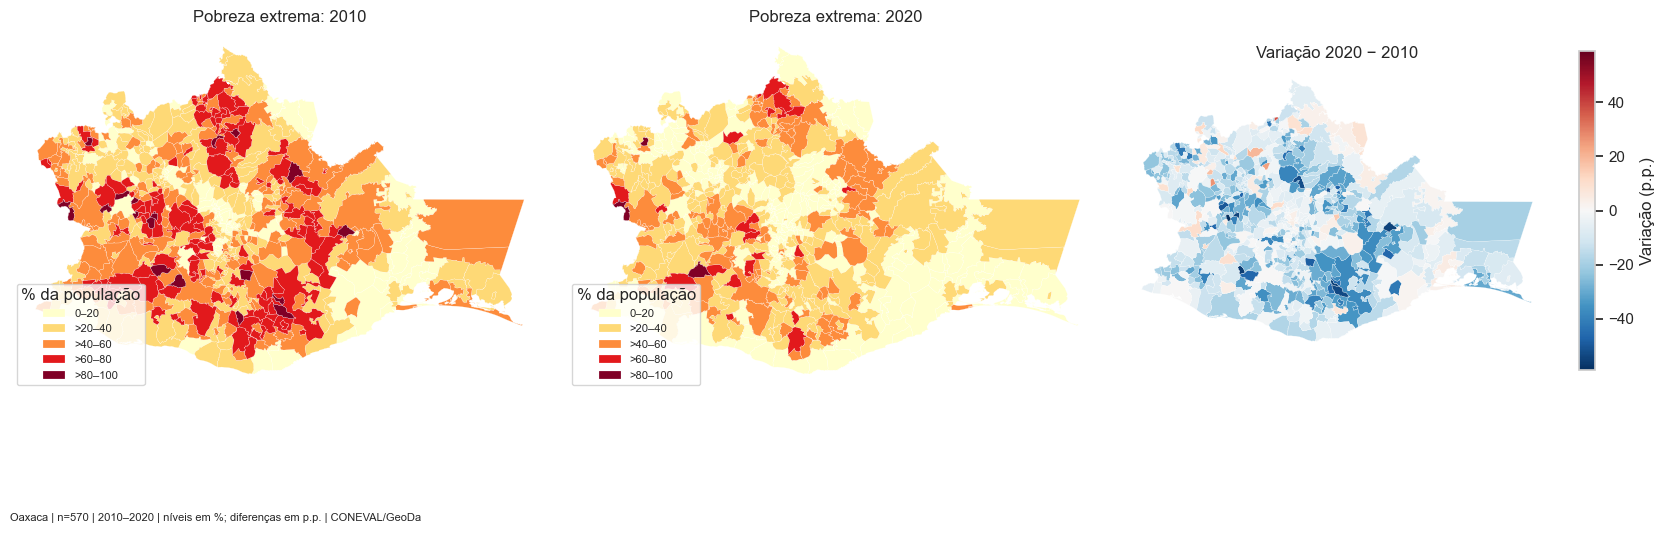

In [11]:
# Comparando os níveis de pobreza extrema em classes iguais nos dois anos
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

mapa.plot(column='pepov_' + '10', ax=axes[0], **estilo_niveis)
axes[0].set_title('Pobreza extrema: 20' + '10')
axes[0].set_axis_off()

mapa.plot(column='pepov_' + '20', ax=axes[1], **estilo_niveis)
axes[1].set_title('Pobreza extrema: 20' + '20')
axes[1].set_axis_off()

# Centrando a escala da variação em zero para separar redução e aumento
limite = dados['delta_pepov'].abs().max()
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)
mapa.plot(column='delta_pepov', ax=axes[2], norm=norma, **estilo_variacao)
axes[2].set_title('Variação 2020 − 2010')
axes[2].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | 2010–2020 | níveis em %; diferenças em p.p. | CONEVAL/GeoDa', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'mapas_pepov_2010_2020.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** A média municipal passou de 43,49% para 28,71%, uma queda de 14,78 p.p. A comparação com classes iguais mostra o recuo dos níveis elevados. O número de municípios acima de 60% caiu de 150 para 25.

No mapa de mudanças, 505 municípios tiveram queda, 62 tiveram aumento e três ficaram estáveis. A faixa de −58,8 a +37,3 p.p. mostra que a redução teve intensidade desigual. A comparação das taxas é descritiva. A convergência condicional será avaliada com as condições iniciais e os controles no notebook 2.

### 5.2 Pobreza total: níveis e mudança

Comparamos 2010 e 2020 em cinco intervalos fixos de percentuais. Na terceira coluna, azul indica redução e vermelho indica aumento. O centro branco corresponde a variação nula. Os três painéis usam os mesmos 570 municípios.

Aqui usamos `ppov_10` e `ppov_20`, mantendo os cortes da figura anterior. O painel de mudança usa `delta_ppov` e tem amplitude própria. Compare os valores das legendas ao confrontar a intensidade da mudança nos dois desfechos.

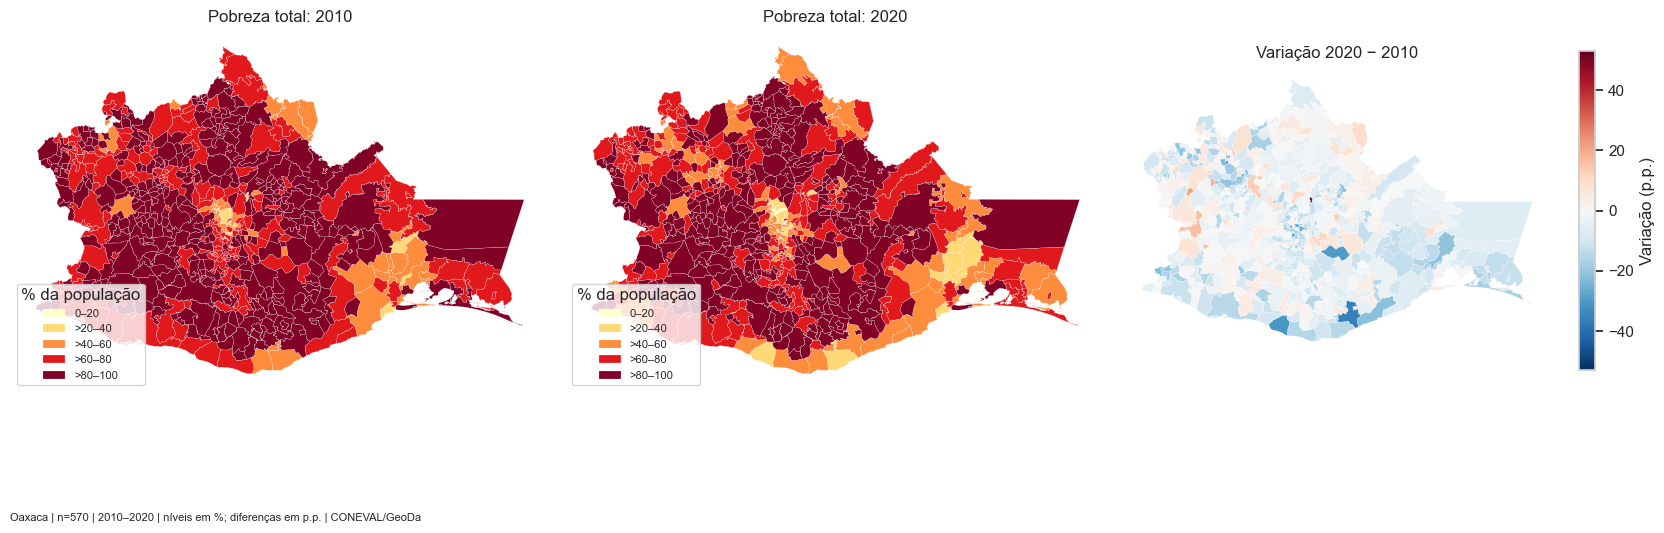

In [12]:
# Comparando os níveis de pobreza total nas mesmas classes da pobreza extrema
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

mapa.plot(column='ppov_' + '10', ax=axes[0], **estilo_niveis)
axes[0].set_title('Pobreza total: 20' + '10')
axes[0].set_axis_off()

mapa.plot(column='ppov_' + '20', ax=axes[1], **estilo_niveis)
axes[1].set_title('Pobreza total: 20' + '20')
axes[1].set_axis_off()

# Ajustando o alcance da escala simétrica à maior mudança absoluta do desfecho
limite = dados['delta_ppov'].abs().max()
norma = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)
mapa.plot(column='delta_ppov', ax=axes[2], norm=norma, **estilo_variacao)
axes[2].set_title('Variação 2020 − 2010')
axes[2].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | 2010–2020 | níveis em %; diferenças em p.p. | CONEVAL/GeoDa', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'mapas_ppov_2010_2020.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** A média municipal caiu de 82,08% para 77,32%, ou 4,75 p.p., diante de 14,78 p.p. para pobreza extrema. Mesmo em 2020, 469 municípios ficaram acima de 60% de pobreza total. As classes iguais mostram como os níveis altos persistem para esse desfecho.

Houve 416 quedas, 151 aumentos e três mudanças nulas. Os extremos foram −36,7 e +52,9 p.p. Essa distribuição mais variada motiva estimar a sensibilidade com a taxa de pobreza total de 2010 como sua própria condição inicial.

### 5.3 Controles socioeconômicos e altitude

Os mapas descrevem as condições iniciais que entrarão nas regressões: escolaridade, língua indígena, saúde e tamanho populacional. Cada painel mantém sua unidade; não se devem comparar diretamente as cores de variáveis com escalas distintas. A altitude é descrita separadamente como controle geográfico, com a ressalva temporal já registrada.

A escolaridade está em anos de estudo. Língua indígena e acesso à saúde estão em porcentagem das respectivas populações de referência. O tamanho municipal entra em logaritmo para comprimir a escala. A grade tem cinco mapas e um espaço vazio.

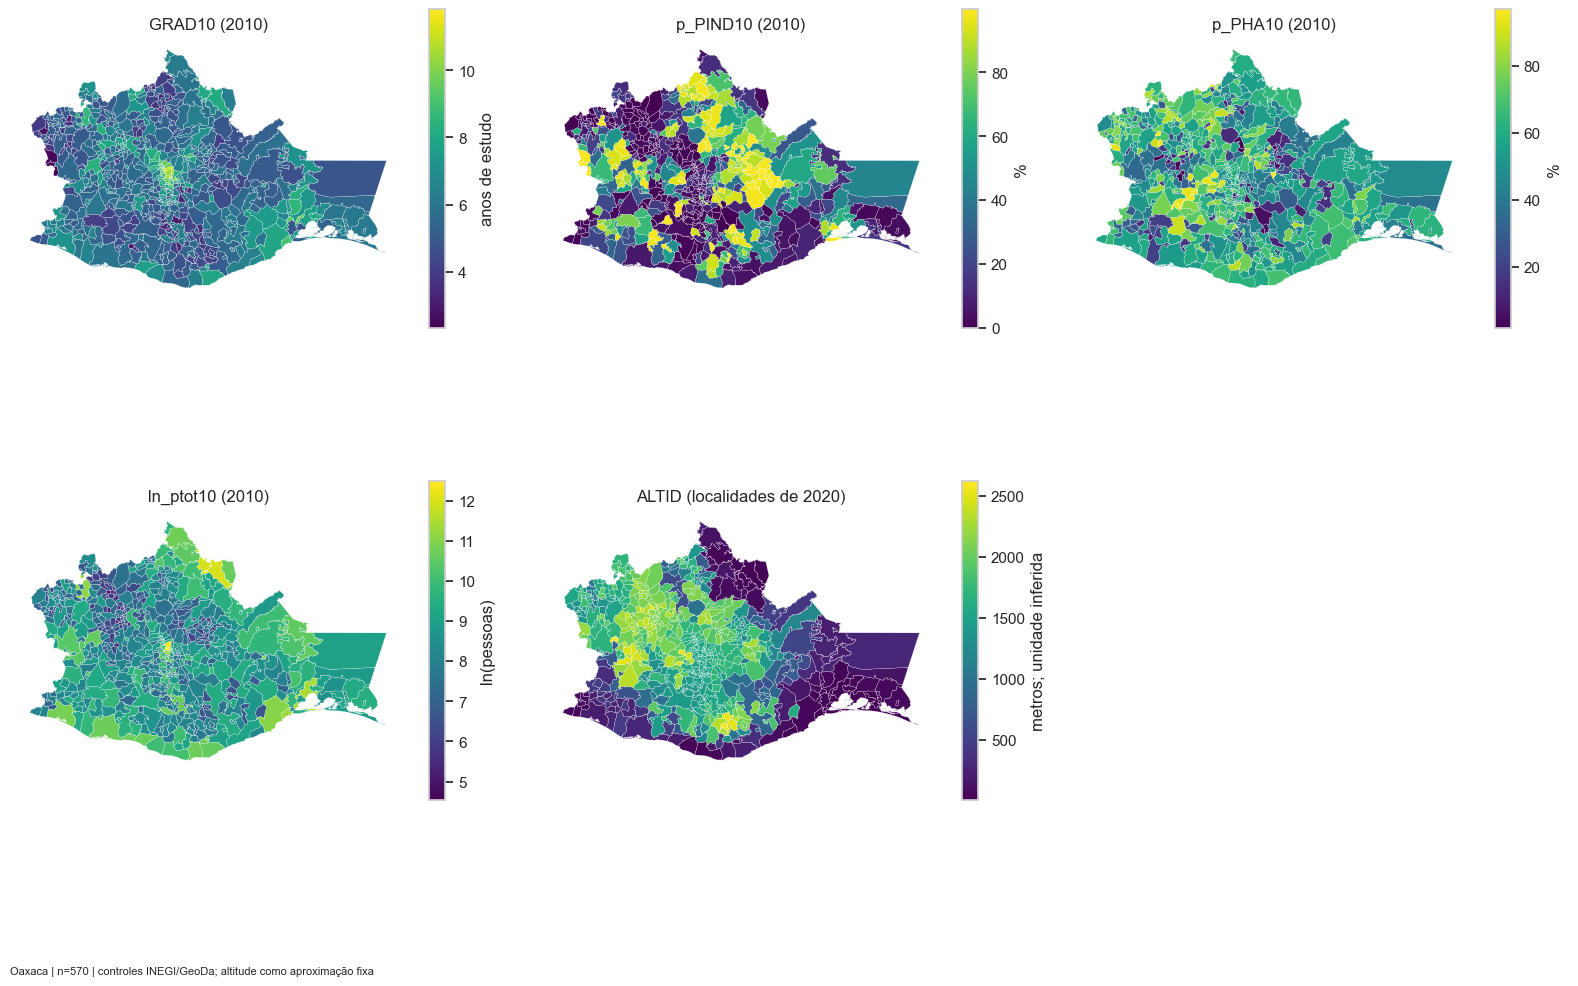

In [13]:
# Mapeando cada controle em sua própria unidade e escala de cores
fig, axes = plt.subplots(2, 3, figsize=(16, 11))

mapa.plot(column='GRAD10', cmap='viridis', legend=True, ax=axes.flat[0], legend_kwds={'label': unidades['GRAD10'], 'shrink': .6}, **borda_municipal)
axes.flat[0].set_title('GRAD10' + ' (2010)')
axes.flat[0].set_axis_off()

mapa.plot(column='p_PIND10', cmap='viridis', legend=True, ax=axes.flat[1], legend_kwds={'label': unidades['p_PIND10'], 'shrink': .6}, **borda_municipal)
axes.flat[1].set_title('p_PIND10' + ' (2010)')
axes.flat[1].set_axis_off()

mapa.plot(column='p_PHA10', cmap='viridis', legend=True, ax=axes.flat[2], legend_kwds={'label': unidades['p_PHA10'], 'shrink': .6}, **borda_municipal)
axes.flat[2].set_title('p_PHA10' + ' (2010)')
axes.flat[2].set_axis_off()

mapa.plot(column='ln_ptot10', cmap='viridis', legend=True, ax=axes.flat[3], legend_kwds={'label': unidades['ln_ptot10'], 'shrink': .6}, **borda_municipal)
axes.flat[3].set_title('ln_ptot10' + ' (2010)')
axes.flat[3].set_axis_off()

mapa.plot(column='ALTID', cmap='viridis', legend=True, ax=axes.flat[4], legend_kwds={'label': unidades['ALTID'], 'shrink': .6}, **borda_municipal)
axes.flat[4].set_title('ALTID (localidades de 2020)')
axes.flat[4].set_axis_off()

# Ocultando o painel que sobra na grade de cinco controles
axes.flat[-1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | controles INEGI/GeoDa; altitude como aproximação fixa', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'mapas_controles.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** Os painéis mostram amplitudes consideráveis. A escolaridade vai de 2,32 a 11,82 anos, a proporção de falantes de língua indígena vai de 0 a 99,75% e o acesso à saúde vai de 1,65 a 96,80%. Essas diferenças mostram por que a comparação das trajetórias precisa considerar o perfil inicial de cada município.

O logaritmo torna legível a diferença entre municípios com 93 e 263.357 habitantes. A altitude representa a média das localidades e serve de aproximação geográfica. Como cada painel usa sua escala, cores semelhantes entre controles correspondem a valores e unidades diferentes.

### 5.4 Distribuições da pobreza extrema

Os histogramas mostram quantos municípios se encontram em cada faixa de pobreza ou de mudança. A comparação ajuda a distinguir a queda da média de uma eventual redução de dispersão. No último painel, valores abaixo de zero são reduções, não taxas de crescimento negativas.

Cada histograma usa 25 faixas, com a altura das barras medida em número de municípios. Os dois primeiros painéis mostram taxas em porcentagem e o terceiro mostra diferenças em pontos percentuais. Compare o deslocamento das distribuições de nível e observe em que lado do zero se concentram as mudanças.

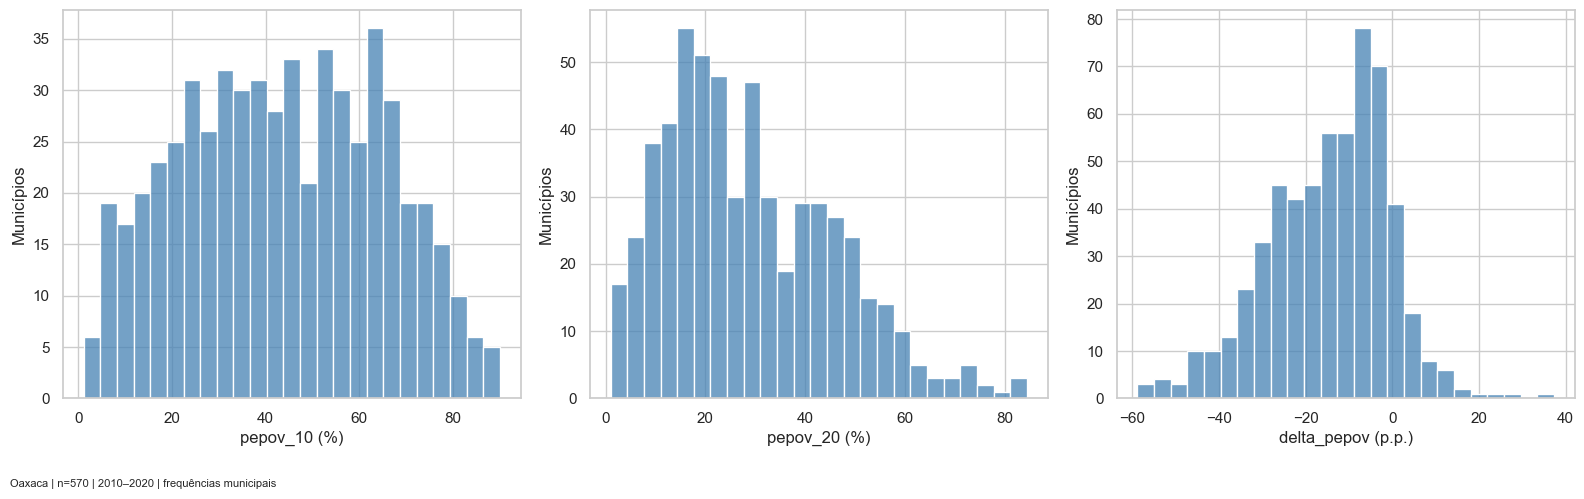

In [14]:
# Contando municípios por faixa de pobreza ou de variação
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(dados['pepov_10'], bins=25, ax=axes[0], color='steelblue')
# Rotulando o eixo em percentual ou pontos percentuais conforme a variável
axes[0].set_xlabel('pepov_10' + ' (' + unidades['pepov_10'] + ')')
axes[0].set_ylabel('Municípios')

sns.histplot(dados['pepov_20'], bins=25, ax=axes[1], color='steelblue')
# Rotulando o eixo em percentual ou pontos percentuais conforme a variável
axes[1].set_xlabel('pepov_20' + ' (' + unidades['pepov_20'] + ')')
axes[1].set_ylabel('Municípios')

sns.histplot(dados['delta_pepov'], bins=25, ax=axes[2], color='steelblue')
# Rotulando o eixo em percentual ou pontos percentuais conforme a variável
axes[2].set_xlabel('delta_pepov' + ' (' + unidades['delta_pepov'] + ')')
axes[2].set_ylabel('Municípios')

# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | 2010–2020 | frequências municipais', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'distribuicoes_pobreza_extrema.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** Os histogramas de nível mostram uma distribuição deslocada para taxas menores em 2020. O painel de mudanças se concentra no lado negativo. A média é de −14,78 p.p., com desvio-padrão de 14,06 p.p. Essa dispersão indica que municípios com queda tiveram trajetórias bastante distintas, além dos 62 com aumento.

O desvio-padrão das mudanças mede heterogeneidade nas trajetórias individuais. A sigma-convergência será examinada comparando a dispersão dos níveis municipais entre os dois anos.

## 6. Vizinhança espacial

Selecionamos a amostra completa, mantemos os códigos ordenados e projetamos os centroides em EPSG:6372 antes de calcular distâncias. Construímos explicitamente a Queen por contato de borda ou vértice e a KNN-5 pelos cinco centroides mais próximos.

Os dois blocos seguintes conferem a diagonal, as ilhas, as componentes e a soma dos pesos e imprimem as propriedades de cada rede. A KNN conserva a direção original das ligações. O CSV reúne os valores detalhados para conferência.

In [15]:
# Selecionando os casos completos e projetando os centroides para calcular distâncias
base = dados.loc[dados['amostra_extrema'].eq(1)].copy().reset_index(drop=True)
ids = base['mun'].tolist()
base_metrica = base.to_crs(CRS_METRICO)
centros = base_metrica.centroid
coordenadas = np.column_stack([centros.x, centros.y])
assert len(np.unique(coordenadas, axis=0)) == len(base)
# Construindo a Queen por contiguidade e a KNN pelos cinco centroides mais próximos
queen = libpysal.weights.Queen.from_dataframe(base, ids=ids)
knn = libpysal.weights.KNN.from_array(coordenadas, k=5, ids=ids)
resumo_pesos = []

### 6.1 Conferência da matriz queen

Imprimimos os graus, as componentes, as ilhas e a assimetria. A padronização faz a soma de cada linha valer um. A comparação da matriz binária com sua transposta conta ligações que existem em apenas uma direção.

In [16]:
# Conferindo a matriz queen e normalizando suas linhas
assert queen.id_order == ids and not queen.islands and np.all(queen.sparse.diagonal() == 0)
queen.transform = 'r'
assert np.allclose(np.asarray(queen.sparse.sum(axis=1)).ravel(), 1)
card = pd.Series(queen.cardinalities)

# Medindo a reciprocidade a partir da matriz binária de vizinhança
binaria = (queen.sparse != 0).astype(int)
sem_reciproca = (binaria - binaria.multiply(binaria.T)).nnz
resumo_pesos.append({'matriz': 'queen', 'n': queen.n, 'vizinhos_min': card.min(),
    'vizinhos_max': card.max(), 'vizinhos_media': card.mean(), 'vizinhos_mediana': card.median(),
    'densidade_pct_n2': queen.pct_nonzero, 'ilhas': len(queen.islands),
    'componentes': queen.n_components, 'arestas_sem_reciproca': sem_reciproca})
print('Matriz queen | municípios:', queen.n)
print('Vizinhos mínimo, médio e máximo:', card.min(), card.mean(), card.max())
print('Componentes:', queen.n_components, '| ilhas:', len(queen.islands))
print('Ligações direcionadas sem recíproca:', sem_reciproca)

Matriz queen | municípios: 570
Vizinhos mínimo, médio e máximo: 1 5.8 22
Componentes: 1 | ilhas: 0
Ligações direcionadas sem recíproca: 0


**Leitura da Queen.** A rede tem uma componente e nenhuma ilha. O número de vizinhos vai de 1 a 22, com média 5,8. A vizinhança binária é recíproca. Os pesos padronizados podem diferir entre direções quando os municípios têm números distintos de vizinhos.

### 6.1 Conferência da matriz knn5

Imprimimos os graus, as componentes, as ilhas e a assimetria. A padronização faz a soma de cada linha valer um. A comparação da matriz binária com sua transposta conta ligações que existem em apenas uma direção.

In [17]:
# Conferindo a matriz knn5 e normalizando suas linhas
assert knn.id_order == ids and not knn.islands and np.all(knn.sparse.diagonal() == 0)
knn.transform = 'r'
assert np.allclose(np.asarray(knn.sparse.sum(axis=1)).ravel(), 1)
card = pd.Series(knn.cardinalities)

# Medindo a reciprocidade a partir da matriz binária de vizinhança
binaria = (knn.sparse != 0).astype(int)
sem_reciproca = (binaria - binaria.multiply(binaria.T)).nnz
resumo_pesos.append({'matriz': 'knn5', 'n': knn.n, 'vizinhos_min': card.min(),
    'vizinhos_max': card.max(), 'vizinhos_media': card.mean(), 'vizinhos_mediana': card.median(),
    'densidade_pct_n2': knn.pct_nonzero, 'ilhas': len(knn.islands),
    'componentes': knn.n_components, 'arestas_sem_reciproca': sem_reciproca})
print('Matriz knn5 | municípios:', knn.n)
print('Vizinhos mínimo, médio e máximo:', card.min(), card.mean(), card.max())
print('Componentes:', knn.n_components, '| ilhas:', len(knn.islands))
print('Ligações direcionadas sem recíproca:', sem_reciproca)
pd.DataFrame(resumo_pesos).to_csv(tabelas / 'resumo_pesos.csv', index=False, encoding='utf-8-sig')

Matriz knn5 | municípios: 570
Vizinhos mínimo, médio e máximo: 5 5.0 5
Componentes: 1 | ilhas: 0
Ligações direcionadas sem recíproca: 680


**Leitura da KNN-5.** Todos os municípios têm cinco vizinhos, mas há 680 ligações direcionadas sem recíproca. A rede tem uma componente e nenhuma ilha. A comparação com Queen modifica os pares de municípios conectados e permite examinar a sensibilidade à definição de proximidade.

### 6.1 Grafos e número de vizinhos

Os grafos tornam visíveis as ligações utilizadas nos cálculos; os histogramas mostram sua distribuição por município. Queen admite números diferentes de vizinhos, enquanto KNN fixa cinco ligações de saída. Os grafos não representam fluxos econômicos observados: são definições de proximidade adotadas antes da estimação.

Na primeira linha, as ligações conectam centroides sobre a malha de Oaxaca. Na segunda, as barras contam os municípios por número de vizinhos. A figura permite distinguir concentração de linhas no espaço, distribuição dos graus e conectividade da rede.

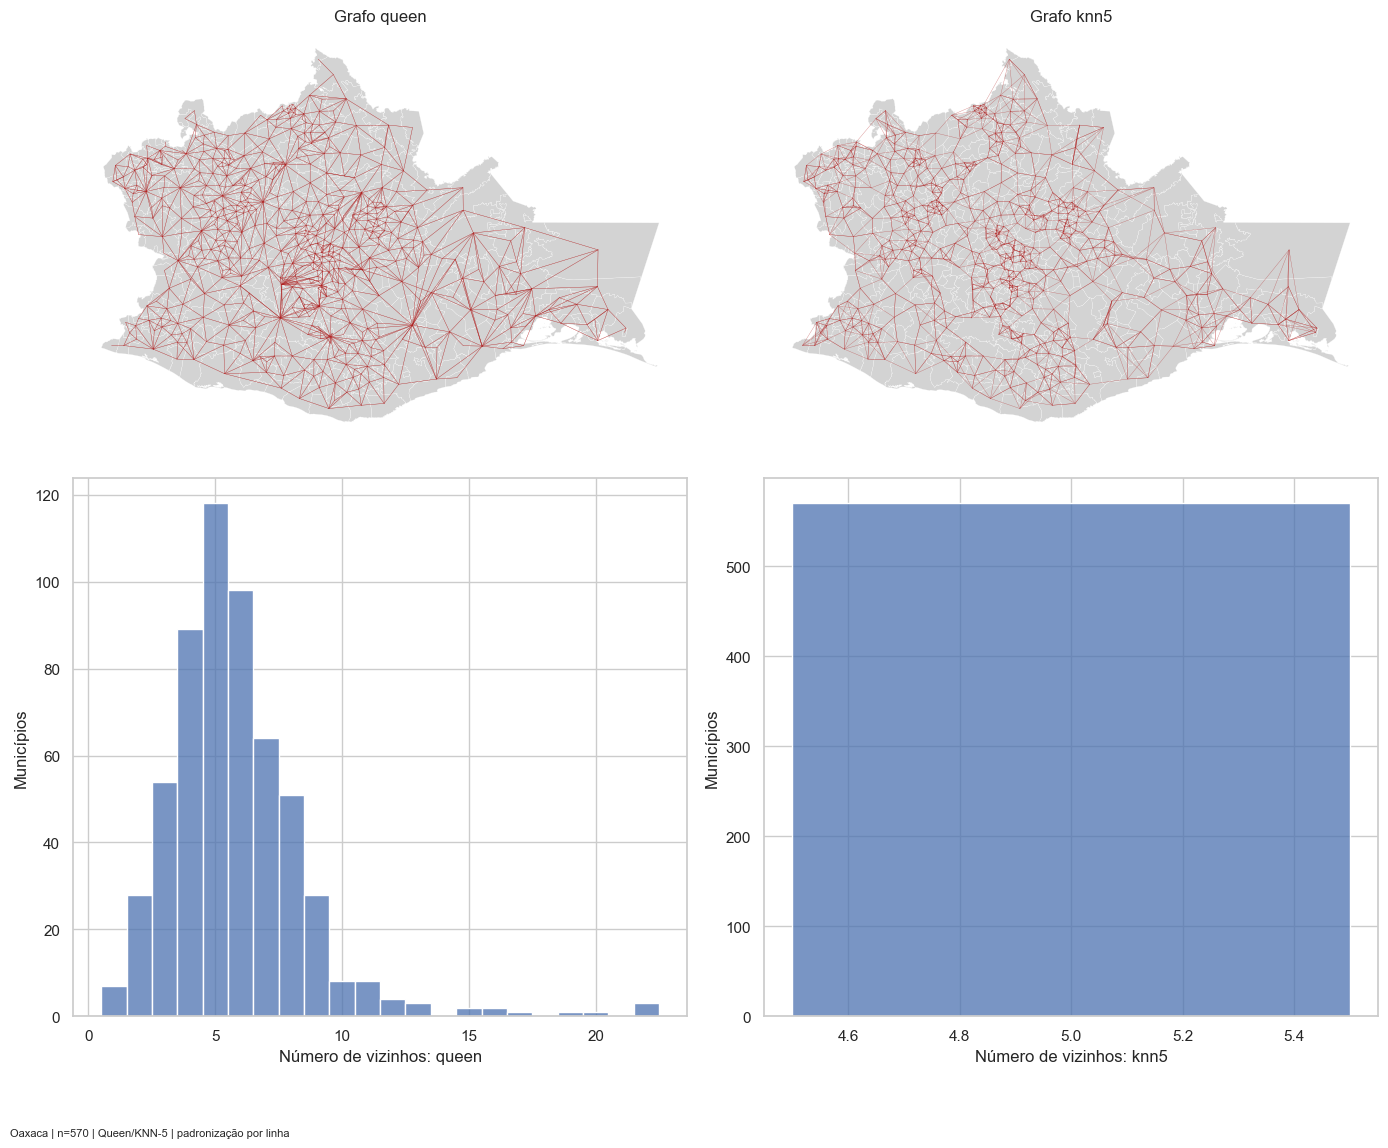

In [18]:
# Sobrepondo as ligações de vizinhança aos limites municipais
base_grafo = base_metrica.set_index('mun', drop=False)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

base_grafo.plot(ax=axes[0, 0], color='lightgray', edgecolor='white', linewidth=.15)
queen.plot(base_grafo, ax=axes[0, 0], edge_kws={'color': 'firebrick', 'linewidth': .25, 'alpha': .6},
    node_kws={'marker': ''})
axes[0, 0].set_title('Grafo ' + 'queen')
axes[0, 0].set_axis_off()
# Contando os municípios por número de vizinhos em cada matriz
sns.histplot(list(queen.cardinalities.values()), discrete=True, ax=axes[1, 0])
axes[1, 0].set(xlabel='Número de vizinhos: ' + 'queen', ylabel='Municípios')

base_grafo.plot(ax=axes[0, 1], color='lightgray', edgecolor='white', linewidth=.15)
knn.plot(base_grafo, ax=axes[0, 1], edge_kws={'color': 'firebrick', 'linewidth': .25, 'alpha': .6},
    node_kws={'marker': ''})
axes[0, 1].set_title('Grafo ' + 'knn5')
axes[0, 1].set_axis_off()
# Contando os municípios por número de vizinhos em cada matriz
sns.histplot(list(knn.cardinalities.values()), discrete=True, ax=axes[1, 1])
axes[1, 1].set(xlabel='Número de vizinhos: ' + 'knn5', ylabel='Municípios')

# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | Queen/KNN-5 | padronização por linha', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'grafos_histogramas_pesos.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O histograma da Queen tem graus entre 1 e 22, com média de 5,8. O da KNN-5 concentra todos os 570 municípios no grau cinco. Os grafos correspondentes ilustram a diferença entre vizinhança por contato territorial e vizinhança por distância entre centroides.

Ambas as redes têm uma componente e nenhuma ilha. Na KNN-5, 680 ligações direcionadas carecem de recíproca. Assim, mesmo com graus médios próximos, as matrizes podem atribuir médias de vizinhança diferentes ao mesmo município.

## 7. Moran global e local

Moran global mede associação espacial dos valores. O local (LISA) identifica municípios com combinações de valores próprios e dos vizinhos. Calculamos os níveis de 2010/2020 e sua diferença em ambas as matrizes, sempre com 999 permutações e semente 42.

p_sim segue a convenção de pseudo-p do ESDA; p_norm é bilateral e analítico. Os mapas LISA usam p_sim < 5%, sem correção de testes múltiplos, apenas para exploração. Na variação, alto/baixo é relativo à média: um cluster baixo–baixo pode concentrar reduções mais intensas. Não se deve aplicar esse teste de variável bruta aos resíduos de uma regressão.

O Moran global resume o alinhamento entre cada valor padronizado e a média de seus vizinhos. O local classifica pares alto–alto, baixo–baixo e contrastes espaciais quando o p-valor de permutação é inferior a 5%. Os CSVs separam o resumo por variável e matriz dos resultados locais por município.

In [19]:
# Preparando os rótulos e a aparência comum aos mapas e diagramas
globais, locais, resultados_moran, resultados_lisa = {}, {}, [], []
rotulos = {0: 'Não significativo', 1: 'Alto–Alto', 2: 'Baixo–Alto', 3: 'Baixo–Baixo', 4: 'Alto–Baixo'}
traducao = {'High-High': 'Alto–Alto', 'Low-High': 'Baixo–Alto', 'Low-Low': 'Baixo–Baixo',
    'High-Low': 'Alto–Baixo', 'Insignificant': 'Não significativo'}
estilo_dispersao_moran = {'s': 10, 'alpha': .55}
estilo_lisa = {'crit_value': ALFA, 'legend': True, **borda_municipal,
    'legend_kwds': {'loc': 'lower left', 'fontsize': 8}}

### 7. Moran de pepov_10 com queen

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [20]:
# Estimando Moran global e local de pepov_10 com queen
valores = base['pepov_10'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, queen, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, queen, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('queen', 'pepov_10')] = mi
locais[('queen', 'pepov_10')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'pepov_10', 'matriz': 'queen', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'pepov_10', 'matriz': 'queen',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('pepov_10 | queen')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

pepov_10 | queen
Moran I: 0.5002331041046281 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 1.7547051127991644e-84
Municípios com indicação local a 5%: 191
Categorias locais: {'Não significativo': 379, 'Baixo–Baixo': 93, 'Alto–Alto': 81, 'Alto–Baixo': 11, 'Baixo–Alto': 6}


**Leitura das estatísticas.** O Moran global é 0,5002, com p de permutação de 0,001. Dos 191 municípios com indicação local nominal, 81 estão em alto–alto e 93 em baixo–baixo.

O predomínio dos dois quadrantes de semelhança indica agrupamento de níveis altos e baixos já em 2010. A Queen define a proximidade pelo contato entre municípios. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.1 Queen e níveis em 2010

O painel à esquerda cruza `pepov_10` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz Queen. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

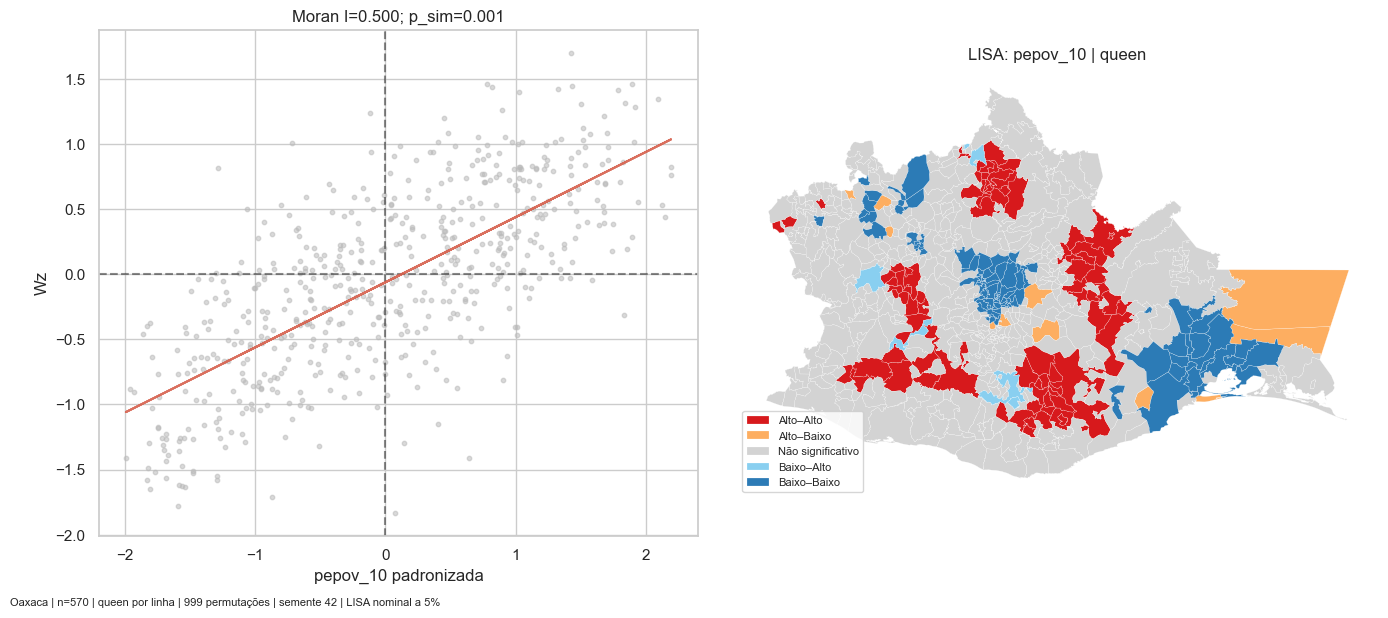

In [21]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('queen', 'pepov_10')], locais[('queen', 'pepov_10')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='pepov_10 padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: pepov_10 | queen')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | queen por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_pepov_10_queen.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,5002, com p de permutação de 0,001. Dos 191 municípios com indicação local nominal, 81 estão em alto–alto e 93 em baixo–baixo.

O predomínio dos dois quadrantes de semelhança indica agrupamento de níveis altos e baixos já em 2010. A Queen define a proximidade pelo contato entre municípios. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Moran de pepov_20 com queen

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [22]:
# Estimando Moran global e local de pepov_20 com queen
valores = base['pepov_20'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, queen, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, queen, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('queen', 'pepov_20')] = mi
locais[('queen', 'pepov_20')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'pepov_20', 'matriz': 'queen', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'pepov_20', 'matriz': 'queen',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('pepov_20 | queen')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

pepov_20 | queen
Moran I: 0.4328078615926606 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 8.849191626980605e-64
Municípios com indicação local a 5%: 172
Categorias locais: {'Não significativo': 398, 'Baixo–Baixo': 86, 'Alto–Alto': 65, 'Alto–Baixo': 11, 'Baixo–Alto': 10}


**Leitura das estatísticas.** O Moran global é 0,4328, com p de permutação de 0,001. Dos 172 municípios com indicação local nominal, 65 estão em alto–alto e 86 em baixo–baixo.

O Moran é menor que o de 2010 com a mesma matriz. A semelhança entre vizinhos continua presente em 2020, mesmo após o recuo da média municipal. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.2 Queen e níveis em 2020

O painel à esquerda cruza `pepov_20` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz Queen. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

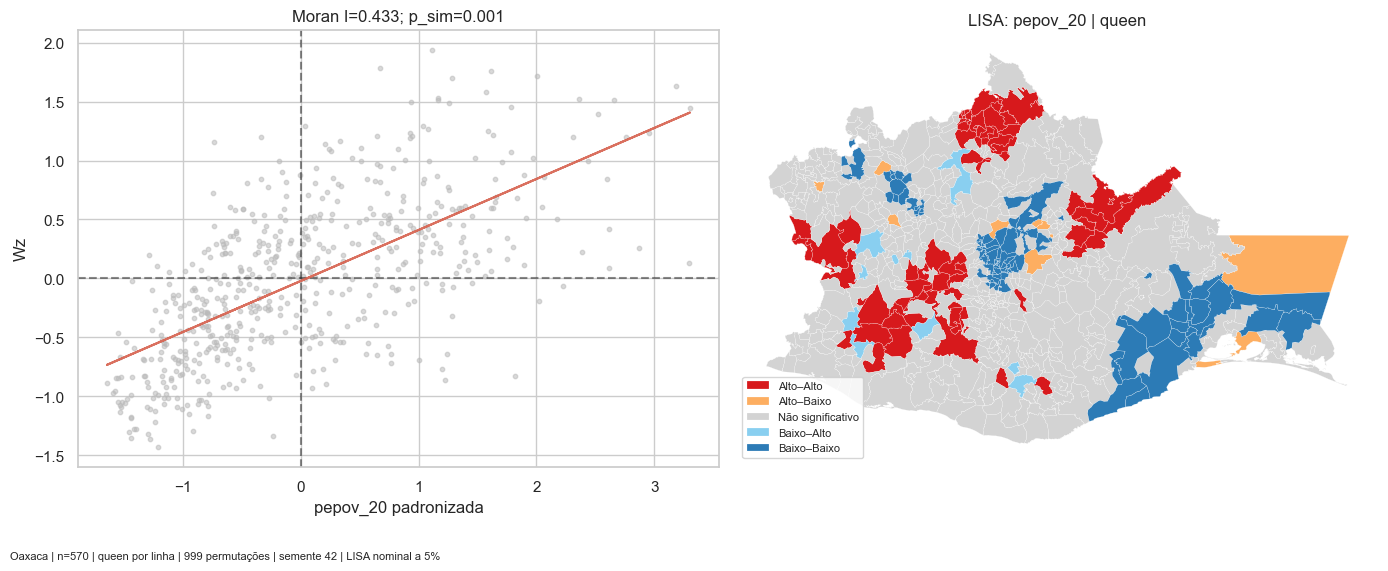

In [23]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('queen', 'pepov_20')], locais[('queen', 'pepov_20')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='pepov_20 padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: pepov_20 | queen')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | queen por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_pepov_20_queen.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,4328, com p de permutação de 0,001. Dos 172 municípios com indicação local nominal, 65 estão em alto–alto e 86 em baixo–baixo.

O Moran é menor que o de 2010 com a mesma matriz. A semelhança entre vizinhos continua presente em 2020, mesmo após o recuo da média municipal. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Moran de delta_pepov com queen

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [24]:
# Estimando Moran global e local de delta_pepov com queen
valores = base['delta_pepov'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, queen, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, queen, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('queen', 'delta_pepov')] = mi
locais[('queen', 'delta_pepov')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'delta_pepov', 'matriz': 'queen', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'delta_pepov', 'matriz': 'queen',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('delta_pepov | queen')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

delta_pepov | queen
Moran I: 0.25547537653155944 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 1.8646480487711843e-23
Municípios com indicação local a 5%: 136
Categorias locais: {'Não significativo': 434, 'Alto–Alto': 66, 'Baixo–Baixo': 43, 'Baixo–Alto': 16, 'Alto–Baixo': 11}


**Leitura das estatísticas.** O Moran global é 0,2555, com p de permutação de 0,001. Dos 136 municípios com indicação local nominal, 66 estão em alto–alto e 43 em baixo–baixo.

As mudanças têm associação espacial positiva mais fraca que os níveis. Baixo–baixo indica mudanças abaixo da média, compatíveis com reduções mais intensas. Alto–alto pode incluir reduções menores que a média. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.3 Queen e mudanças entre 2010 e 2020

O painel à esquerda cruza `delta_pepov` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz Queen. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

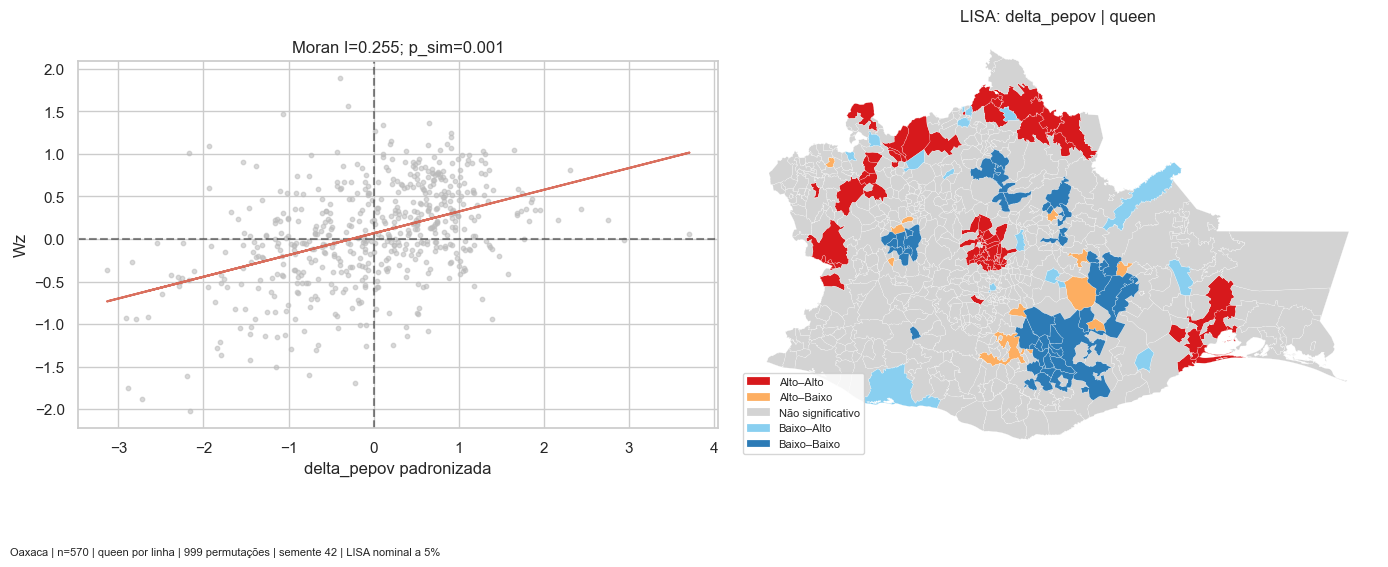

In [25]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('queen', 'delta_pepov')], locais[('queen', 'delta_pepov')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='delta_pepov padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: delta_pepov | queen')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | queen por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_delta_pepov_queen.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,2555, com p de permutação de 0,001. Dos 136 municípios com indicação local nominal, 66 estão em alto–alto e 43 em baixo–baixo.

As mudanças têm associação espacial positiva mais fraca que os níveis. Baixo–baixo indica mudanças abaixo da média, compatíveis com reduções mais intensas. Alto–alto pode incluir reduções menores que a média. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Moran de pepov_10 com knn5

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [26]:
# Estimando Moran global e local de pepov_10 com knn5
valores = base['pepov_10'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, knn, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, knn, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('knn5', 'pepov_10')] = mi
locais[('knn5', 'pepov_10')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'pepov_10', 'matriz': 'knn5', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'pepov_10', 'matriz': 'knn5',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('pepov_10 | knn5')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

pepov_10 | knn5
Moran I: 0.5602203841744855 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 2.5265705173052707e-114
Municípios com indicação local a 5%: 212
Categorias locais: {'Não significativo': 358, 'Baixo–Baixo': 103, 'Alto–Alto': 95, 'Baixo–Alto': 9, 'Alto–Baixo': 5}


**Leitura das estatísticas.** O Moran global é 0,5602, com p de permutação de 0,001. Dos 212 municípios com indicação local nominal, 95 estão em alto–alto e 103 em baixo–baixo.

A associação de níveis em 2010 também aparece quando cada município tem cinco vizinhos por distância. O I é maior que sob Queen, e a diferença é descritiva porque as matrizes definem pares diferentes. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.4 KNN-5 e níveis em 2010

O painel à esquerda cruza `pepov_10` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz KNN-5. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

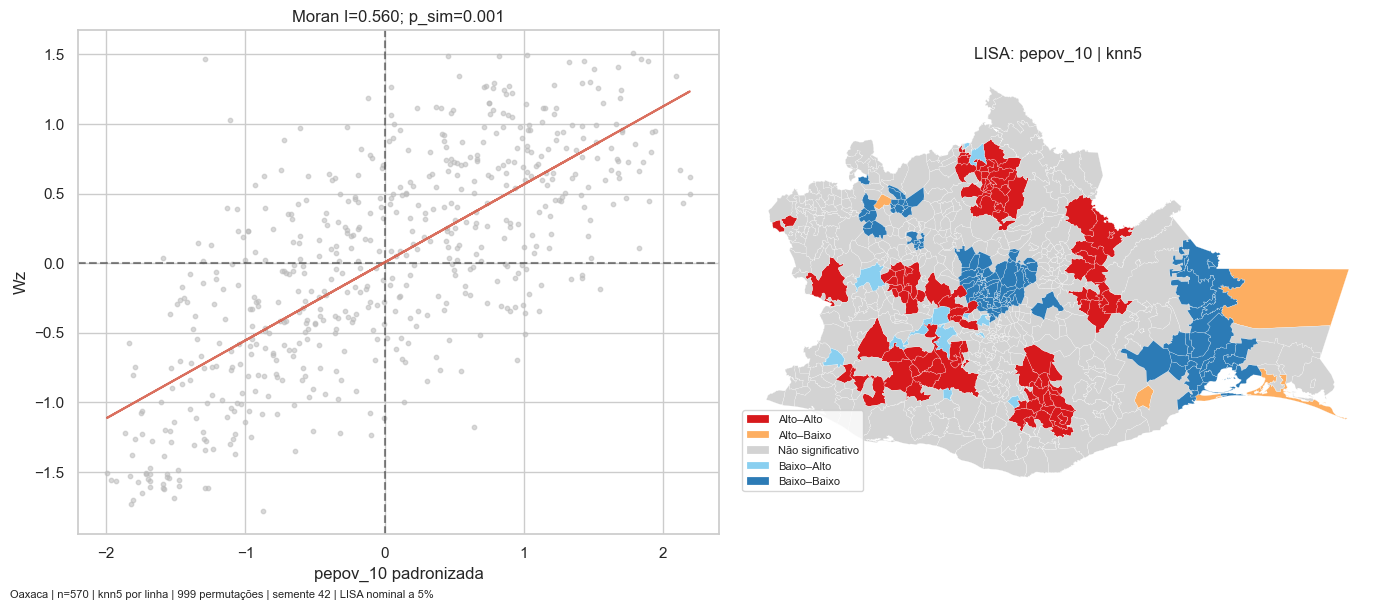

In [27]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('knn5', 'pepov_10')], locais[('knn5', 'pepov_10')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='pepov_10 padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: pepov_10 | knn5')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | knn5 por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_pepov_10_knn5.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,5602, com p de permutação de 0,001. Dos 212 municípios com indicação local nominal, 95 estão em alto–alto e 103 em baixo–baixo.

A associação de níveis em 2010 também aparece quando cada município tem cinco vizinhos por distância. O I é maior que sob Queen, e a diferença é descritiva porque as matrizes definem pares diferentes. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Moran de pepov_20 com knn5

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [28]:
# Estimando Moran global e local de pepov_20 com knn5
valores = base['pepov_20'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, knn, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, knn, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('knn5', 'pepov_20')] = mi
locais[('knn5', 'pepov_20')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'pepov_20', 'matriz': 'knn5', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'pepov_20', 'matriz': 'knn5',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('pepov_20 | knn5')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

pepov_20 | knn5
Moran I: 0.4657411241174799 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 1.0446619959048759e-79
Municípios com indicação local a 5%: 197
Categorias locais: {'Não significativo': 373, 'Baixo–Baixo': 108, 'Alto–Alto': 70, 'Baixo–Alto': 11, 'Alto–Baixo': 8}


**Leitura das estatísticas.** O Moran global é 0,4657, com p de permutação de 0,001. Dos 197 municípios com indicação local nominal, 70 estão em alto–alto e 108 em baixo–baixo.

O I é menor que em 2010 sob a mesma KNN-5. A contagem de baixo–baixo subiu de 103 para 108, enquanto a de alto–alto caiu de 95 para 70. As categorias se referem à média de cada ano. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.5 KNN-5 e níveis em 2020

O painel à esquerda cruza `pepov_20` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz KNN-5. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

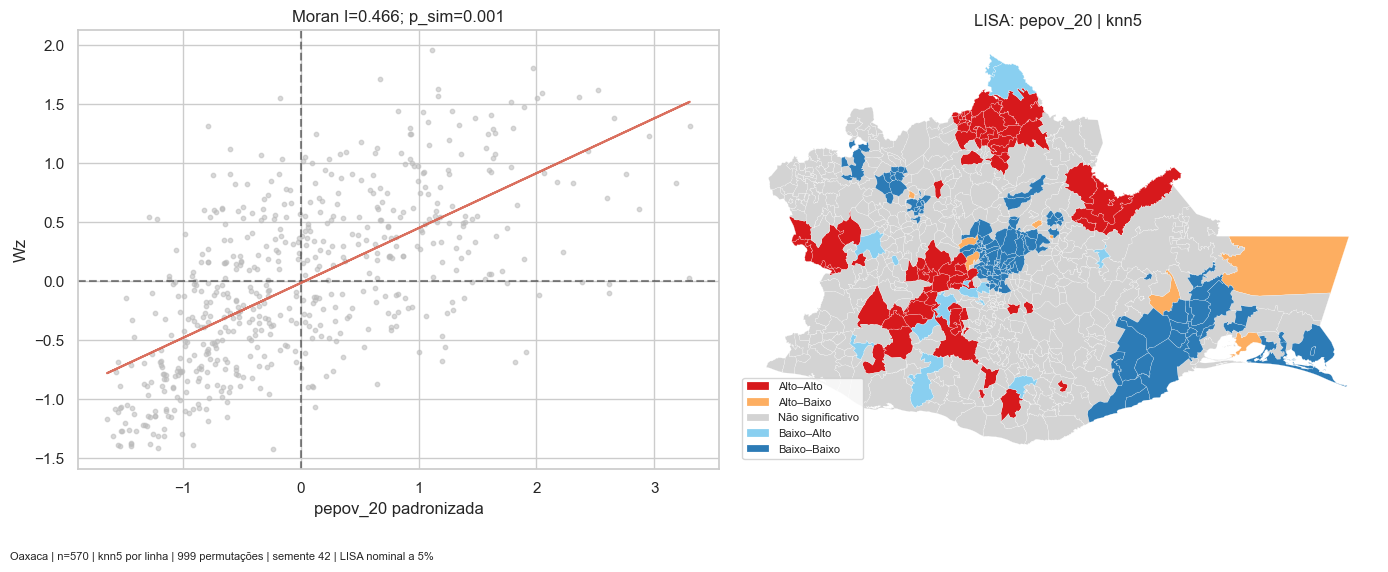

In [29]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('knn5', 'pepov_20')], locais[('knn5', 'pepov_20')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='pepov_20 padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: pepov_20 | knn5')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | knn5 por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_pepov_20_knn5.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,4657, com p de permutação de 0,001. Dos 197 municípios com indicação local nominal, 70 estão em alto–alto e 108 em baixo–baixo.

O I é menor que em 2010 sob a mesma KNN-5. A contagem de baixo–baixo subiu de 103 para 108, enquanto a de alto–alto caiu de 95 para 70. As categorias se referem à média de cada ano. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Moran de delta_pepov com knn5

Calculamos o Moran global com 999 permutações e o Moran local com a mesma semente. O console informa a estatística, sua referência esperada e os p-valores com convenções identificadas. A contagem por categoria resume a localização de agrupamentos exploratórios.

In [30]:
# Estimando Moran global e local de delta_pepov com knn5
valores = base['delta_pepov'].to_numpy(float)
np.random.seed(SEMENTE)
mi = esda.Moran(valores, knn, permutations=PERMUTACOES, two_tailed=True)
lisa = esda.Moran_Local(valores, knn, permutations=PERMUTACOES, seed=SEMENTE,
    n_jobs=1, keep_simulations=False)
globais[('knn5', 'delta_pepov')] = mi
locais[('knn5', 'delta_pepov')] = lisa

# Registrando as estatísticas para exportação e as categorias exploratórias
resultados_moran.append({'variavel': 'delta_pepov', 'matriz': 'knn5', 'I': mi.I,
    'I_esperado': mi.EI, 'z_norm': mi.z_norm, 'p_sim': mi.p_sim,
    'p_norm_bilateral': mi.p_norm, 'permutacoes': PERMUTACOES, 'semente': SEMENTE})
categoria = np.where(lisa.p_sim < ALFA, lisa.q, 0)
resultados_lisa.append(pd.DataFrame({'mun': ids, 'variavel': 'delta_pepov', 'matriz': 'knn5',
    'I_local': lisa.Is, 'quadrante': lisa.q, 'p_sim': lisa.p_sim,
    'categoria': pd.Series(categoria).map(rotulos)}))
print('delta_pepov | knn5')
print('Moran I:', mi.I, '| esperado:', mi.EI)
print('p de permutação:', mi.p_sim, '| p normal bilateral:', mi.p_norm)
print('Municípios com indicação local a 5%:', (lisa.p_sim < ALFA).sum())
print('Categorias locais:', pd.Series(categoria).map(rotulos).value_counts().to_dict())

delta_pepov | knn5
Moran I: 0.26787874310519455 | esperado: -0.0017574692442882249
p de permutação: 0.001 | p normal bilateral: 1.109010561919353e-27
Municípios com indicação local a 5%: 133
Categorias locais: {'Não significativo': 437, 'Alto–Alto': 65, 'Baixo–Baixo': 50, 'Alto–Baixo': 10, 'Baixo–Alto': 8}


**Leitura das estatísticas.** O Moran global é 0,2679, com p de permutação de 0,001. Dos 133 municípios com indicação local nominal, 65 estão em alto–alto e 50 em baixo–baixo.

O I fica próximo do observado na Queen para a mudança, mas a composição dos quadrantes é diferente. As categorias descrevem a mudança relativa à média municipal. Um município alto–alto pode ter registrado queda, desde que menor que a média. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7.6 KNN-5 e mudanças entre 2010 e 2020

O painel à esquerda cruza `delta_pepov` padronizada com sua defasagem espacial, isto é, a média ponderada dos vizinhos pela matriz KNN-5. Cada ponto representa um município. A inclinação resume a associação espacial global. O painel à direita usa a malha projetada para mostrar o quadrante de cada caso com indicação local a 5%, a partir de 999 permutações.

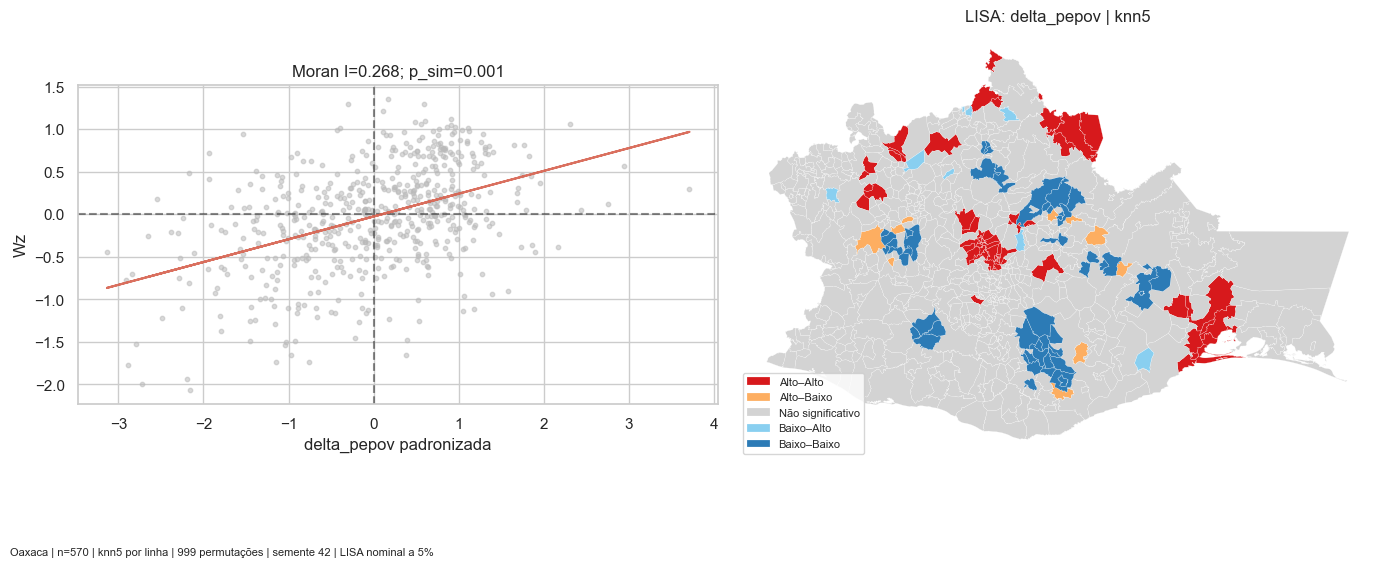

In [31]:
# Selecionando as estatísticas de Moran da variável e da matriz desta figura
mi, lisa = globais[('knn5', 'delta_pepov')], locais[('knn5', 'delta_pepov')]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Traçando a relação entre o valor padronizado e sua média espacial
lisa.plot_scatter(crit_value=None, ax=axes[0], scatter_kwds=estilo_dispersao_moran)
axes[0].set(xlabel='delta_pepov padronizada', ylabel='Wz', title=f'Moran I={mi.I:.3f}; p_sim={mi.p_sim:.3f}')
# Mapeando os quadrantes locais pelo corte nominal de 5%
lisa.plot(base_metrica, ax=axes[1], **estilo_lisa)
# Traduzindo os rótulos da legenda
legenda = axes[1].get_legend().get_texts()
legenda[0].set_text(traducao[legenda[0].get_text()])
legenda[1].set_text(traducao[legenda[1].get_text()])
legenda[2].set_text(traducao[legenda[2].get_text()])
legenda[3].set_text(traducao[legenda[3].get_text()])
legenda[4].set_text(traducao[legenda[4].get_text()])
axes[1].set_title('LISA: delta_pepov | knn5')
axes[1].set_axis_off()
# Exportando a figura em 300 dpi antes de exibi-la no notebook
fig.text(.01, .01, 'Oaxaca | n=570 | knn5 por linha | 999 permutações | semente 42 | LISA nominal a 5%', fontsize=8)
fig.tight_layout(rect=(0, .055, 1, 1))
fig.savefig(figuras / 'moran_lisa_delta_pepov_knn5.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

**Interpretação da figura.** O Moran global é 0,2679, com p de permutação de 0,001. Dos 133 municípios com indicação local nominal, 65 estão em alto–alto e 50 em baixo–baixo.

O I fica próximo do observado na Queen para a mudança, mas a composição dos quadrantes é diferente. As categorias descrevem a mudança relativa à média municipal. Um município alto–alto pode ter registrado queda, desde que menor que a média. O mapa local é exploratório. As indicações usam um corte por município, sem correção por testes múltiplos.

### 7. Exportação dos resultados espaciais

Consolidamos os seis resultados globais e as classificações municipais nos mesmos CSVs de referência. O detalhamento local registra cada código junto à variável e à matriz utilizada.

In [32]:
# Gravando os resultados globais e locais na ordem das análises
moran = pd.DataFrame(resultados_moran)
lisa_municipal = pd.concat(resultados_lisa, ignore_index=True)
moran.to_csv(tabelas / 'moran_global.csv', index=False, encoding='utf-8-sig')
lisa_municipal.to_csv(tabelas / 'lisa_municipal.csv', index=False, encoding='utf-8-sig')
print('Resultados globais gravados:', len(moran))
print('Resultados locais gravados:', len(lisa_municipal))

Resultados globais gravados: 6
Resultados locais gravados: 3420


## 8. Exportação e conferência final

O GeoPackage mantém os campos originais e acrescenta diferenças, logaritmo, regime e indicadores de amostra. O dicionário definido no bloco cobre os campos analíticos e de auditoria; os outros campos preservados remetem aos dicionários originais em data/raw.

O notebook 2 lerá a camada municipios. Reabrimos a exportação para conferir IDs, valores e geometrias e verificamos novamente os hashes dos inputs. As verificações são feitas aqui, sem produzir tabelas técnicas repetidas de validação.

Cada entrada associa a variável a sua fonte, definição, unidade, período e transformação. Os numeradores e denominadores são documentados junto aos campos derivados, de modo que a auditoria dos percentuais possa ser refeita.

In [33]:
# Documentando as fontes, unidades e transformações dos campos analíticos
conceitos = {
 'mun': ('GeoDa/INEGI', 'código dentro de Oaxaca; não é código nacional', 'texto 001–570', 'fixo', 'texto com três posições'),
 'ID': ('GeoDa/INEGI', 'código estadual e municipal', 'código', 'fixo', 'original; 20000+int(mun)'),
 'mun_name': ('GeoDa/INEGI', 'nome municipal; não é chave', 'texto', 'fixo', 'original'),
 'pepov_10': ('CONEVAL/GeoDa', 'população em pobreza extrema', '%', '2010', 'original'),
 'pepov_20': ('CONEVAL/GeoDa', 'população em pobreza extrema', '%', '2020', 'original'),
 'ppov_10': ('CONEVAL/GeoDa', 'população em pobreza total', '%', '2010', 'original'),
 'ppov_20': ('CONEVAL/GeoDa', 'população em pobreza total', '%', '2020', 'original'),
 'GRAD10': ('INEGI/GeoDa', 'média de anos de estudo', 'anos', '2010', 'original'),
 'p_PIND10': ('INEGI/GeoDa', 'falantes de língua indígena na população de 5 anos ou mais', '%', '2010', '100*PIND10/P5U10; original conferido'),
 'p_PHA10': ('INEGI/GeoDa', 'população com acesso à saúde', '%', '2010', '100*PHA10/PTOT10; original conferido'),
 'PTOT10': ('INEGI/GeoDa', 'população censitária', 'pessoas', '2010', 'original'),
 'ALTID': ('INEGI/GeoDa', 'altitude média de localidades de 2020; aproximação fixa', 'metros; inferência da convenção INEGI', '2020', 'original; agregação não descrita'),
 'p_P15AN00': ('INEGI/GeoDa', 'analfabetismo entre pessoas de 15 anos ou mais', '%', '2000', '100*P15AN00/P15U00'),
 'p_ELEC00': ('INEGI/GeoDa', 'domicílios particulares habitados com eletricidade', '%', '2000', '100*ELEC00/HOMS00'),
 'p_NODIR00': ('INEGI/GeoDa', 'domicílios particulares habitados com piso diferente de terra', '%', '2000', '100*NODIR00/HOMS00'),
 'delta_pepov': ('derivada CONEVAL', 'variação extrema; negativo=redução', 'p.p.', '2010–2020', 'pepov_20-pepov_10'),
 'delta_ppov': ('derivada CONEVAL', 'variação total; negativo=redução', 'p.p.', '2010–2020', 'ppov_20-ppov_10'),
 'ln_ptot10': ('derivada INEGI', 'logaritmo natural da população positiva', 'ln(pessoas)', '2010', 'ln(PTOT10)'),
 'regime_indigena': ('derivada INEGI', 'maioria de falantes na população de referência', '0/1', '2010', '1 se p_PIND10>=50; 0 caso contrário'),
 'amostra_extrema': ('derivada', 'caso completo de pobreza extrema', '0/1', '2010–2020', 'finitos em y, pobreza inicial e cinco controles'),
 'amostra_total': ('derivada', 'caso completo de pobreza total', '0/1', '2010–2020', 'finitos em y, pobreza inicial e cinco controles'),
 'amostra_comum': ('derivada', 'interseção das amostras', '0/1', '2010–2020', 'extrema=1 e total=1')}
# Incluindo os componentes das fórmulas auditadas e a geometria municipal
conceitos.update({
 'PIND10': ('INEGI/GeoDa','falantes de língua indígena','pessoas','2010','original; numerador de p_PIND10'),
 'P5U10': ('INEGI/GeoDa','população de 5 anos ou mais','pessoas','2010','original; denominador de p_PIND10'),
 'PHA10': ('INEGI/GeoDa','população com acesso à saúde','pessoas','2010','original; numerador de p_PHA10'),
 'P15AN00': ('INEGI/GeoDa','pessoas de 15 anos ou mais sem ler/escrever','pessoas','2000','original; numerador de p_P15AN00'),
 'P15U00': ('INEGI/GeoDa','população de 15 anos ou mais','pessoas','2000','original; denominador de p_P15AN00'),
 'ELEC00': ('INEGI/GeoDa','domicílios particulares habitados com eletricidade','domicílios','2000','original; numerador de p_ELEC00'),
 'NODIR00': ('INEGI/GeoDa','domicílios particulares habitados com piso diferente de terra','domicílios','2000','original; numerador de p_NODIR00'),
 'HOMS00': ('INEGI/GeoDa','domicílios particulares habitados','domicílios','2000','original; denominador dos indicadores de moradia'),
 'geometry': ('INEGI/GeoDa','geometria municipal; somente sete make_valid autorizados','graus no GPKG; métricas usam EPSG:6372','malha disponível na fonte','originais preservados; reparos documentados')})

### 8.1 Gravação e reabertura

Agora gravamos a camada municipios e seu dicionário. Reabrir o GeoPackage verifica que a exportação conservou os códigos textuais, os valores derivados e as geometrias válidas. O último laço confirma que os dados brutos e materiais das aulas continuam com os mesmos hashes.

A célula grava o dicionário em CSV e o GeoPackage na camada `municipios`. A leitura de conferência compara a ordem dos códigos, a igualdade geométrica e as variáveis calculadas. A comparação final dos hashes usa o mesmo conjunto de entradas registrado no início.

In [34]:
# Gravando o dicionário e a camada que será lida pelo notebook 2
dicionario = pd.DataFrame([{'variavel': k, 'origem': v[0], 'conceito': v[1],
    'unidade': v[2], 'ano': v[3], 'transformacao': v[4]} for k, v in conceitos.items()])
dicionario.to_csv(tratados / 'dicionario_analitico.csv', index=False, encoding='utf-8-sig')
dados.to_file(tratados / 'oaxaca_analise.gpkg', layer='municipios', driver='GPKG', index=False)
# Reabrindo a camada para conferir códigos, geometrias e valores derivados
reaberta = gpd.read_file(tratados / 'oaxaca_analise.gpkg', layer='municipios').sort_values('mun').reset_index(drop=True)
assert reaberta['mun'].tolist() == dados['mun'].tolist()
assert reaberta.geometry.is_valid.all() and reaberta.geometry.geom_equals(dados.geometry).all()
for campo in ['delta_pepov', 'delta_ppov', 'ln_ptot10', *controles]:
    assert np.allclose(reaberta[campo], dados[campo], equal_nan=True)
# Verificando a integridade dos arquivos de entrada pelos hashes
for arquivo, sha256 in hashes_iniciais.items():
    assert hashlib.sha256((raiz / arquivo).read_bytes()).hexdigest() == sha256
print('Base e dicionário exportados; 570 municípios e 21 inputs originais conferidos.')

Base e dicionário exportados; 570 municípios e 21 inputs originais conferidos.
